# 01 · H1: Is the drop in the US share linked more to other markets growing or to US exports falling?

**Hypothesis H1.** The US share of Canada's exports fell more because exports to the rest of the world grew than because exports to the US fell.

**Frozen rule.** Confirmed if the rest-of-world (RoW) side of the decomposition contributes more to the decline than the US side. Rejected otherwise.

**Method in plain words.** The US share is US exports divided by all exports, so it falls when US exports shrink or when exports elsewhere grow. A log decomposition splits the change in the share into those two parts, each weighted by the rest-of-world share of exports.

The simple form uses baseline weights. If its error is above 10% of the total change, the exact form (log-mean weights, which adds up exactly) is used instead. All numbers come from `mart_decomposition`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import analysis
from src.common import load_settings

pd.set_option("display.float_format", "{:,.4f}".format)
con = analysis.connect()
start, end = analysis.tariff_window(con)
print(f"Tariff period (latest 12 months): {start} to {end}")

Tariff period (latest 12 months): Oct 2025 to Sep 2026


## Exports and shares by period

Baseline values are annual equivalents (each calendar month averaged over the baseline years). Values in CAD billions.

In [2]:
rows = []
for baseline, label in analysis.BASELINES.items():
    for variant in ["total", "ex_gold_ex_energy"]:
        r = analysis.h1(con, baseline, variant)
        rows.append({
            "baseline": label, "variant": variant,
            "US, baseline (CAD bn)": r["x_us_base"] / 1e9, "US, latest (CAD bn)": r["x_us_tariff"] / 1e9,
            "RoW, baseline (CAD bn)": r["x_row_base"] / 1e9, "RoW, latest (CAD bn)": r["x_row_tariff"] / 1e9,
            "US share, baseline (%)": 100 * r["s_base"], "US share, latest (%)": 100 * r["s_tariff"],
            "change (pp)": r["d_share_pp"],
        })
pd.DataFrame(rows)

,baseline,variant,"US, baseline (CAD bn)","US, latest (CAD bn)","RoW, baseline (CAD bn)","RoW, latest (CAD bn)","US share, baseline (%)","US share, latest (%)",change (pp)
0,2022–2024,total,549.1684,529.5484,171.5218,251.9141,76.2003,67.7638,-8.4366
1,2022–2024,ex_gold_ex_energy,354.2663,343.4986,128.2999,146.6741,73.4130,70.0771,-3.3359
2,2023–2024,total,546.3829,529.5484,168.7733,251.9141,76.4005,67.7638,-8.6367
3,2023–2024,ex_gold_ex_energy,362.4965,343.4986,125.6258,146.6741,74.2634,70.0771,-4.1864


## Decomposition and verdict

Negative contributions push the US share down. Values are log points × 100 (about a percent change).

In [3]:
rows = []
for baseline, label in analysis.BASELINES.items():
    for variant in ["total", "ex_gold_ex_energy"]:
        r = analysis.h1(con, baseline, variant)
        rows.append({
            "baseline": label, "variant": variant, "form used": r["method"],
            "simple-form error (% of total)": 100 * r["residual_share"],
            "US side": 100 * r["us_side"], "RoW side": 100 * r["row_side"],
            "RoW share of the change (%)": 100 * r["row_share_of_change"],
            "H1 verdict": r["verdict"],
        })
h1_table = pd.DataFrame(rows)
h1_table

,baseline,variant,form used,simple-form error (% of total),US side,RoW side,RoW share of the change (%),H1 verdict
0,2022–2024,total,exact,14.6579,-1.0146,-10.7193,91.3536,confirmed
1,2022–2024,ex_gold_ex_energy,approximation,5.8369,-0.8206,-3.5585,81.2604,confirmed
2,2023–2024,total,exact,15.0486,-0.8694,-11.1268,92.7528,confirmed
3,2023–2024,ex_gold_ex_energy,approximation,7.4139,-1.3854,-3.9867,74.2107,confirmed


In [4]:
for baseline, label in analysis.BASELINES.items():
    r = analysis.h1(con, baseline, "total")
    print(f"Baseline {label}: H1 {r['verdict'].upper()}. The RoW side contributes {-100 * r['row_side']:.1f} "
          f"log points to the decline and the US side {-100 * r['us_side']:.1f} "
          f"({r['row_share_of_change']:.0%} of the change is on the RoW side; {r['method']} form).")
verdicts = set(h1_table["H1 verdict"])
print("Verdict is the same for both baselines and both variants." if len(verdicts) == 1
      else f"Verdicts differ: {verdicts}")

Baseline 2022–2024: H1 CONFIRMED. The RoW side contributes 10.7 log points to the decline and the US side 1.0 (91% of the change is on the RoW side; exact form).
Baseline 2023–2024: H1 CONFIRMED. The RoW side contributes 11.1 log points to the decline and the US side 0.9 (93% of the change is on the RoW side; exact form).
Verdict is the same for both baselines and both variants.


## Charts

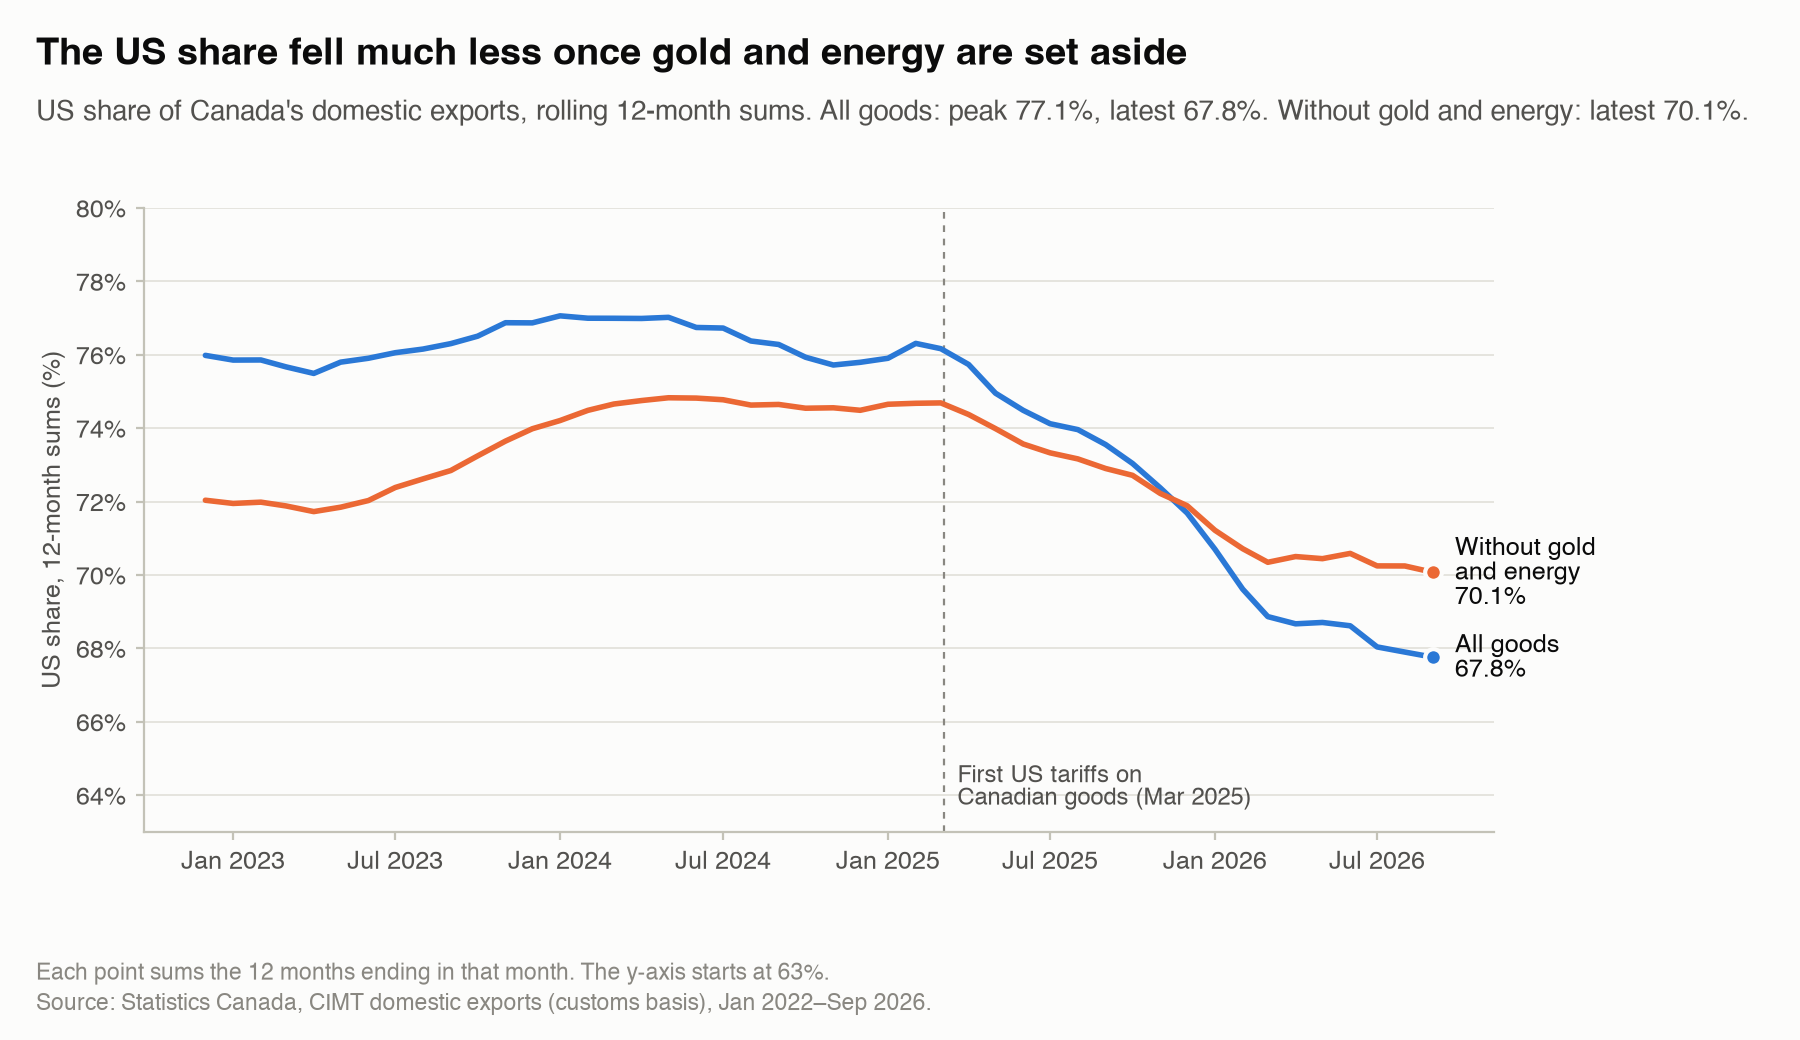

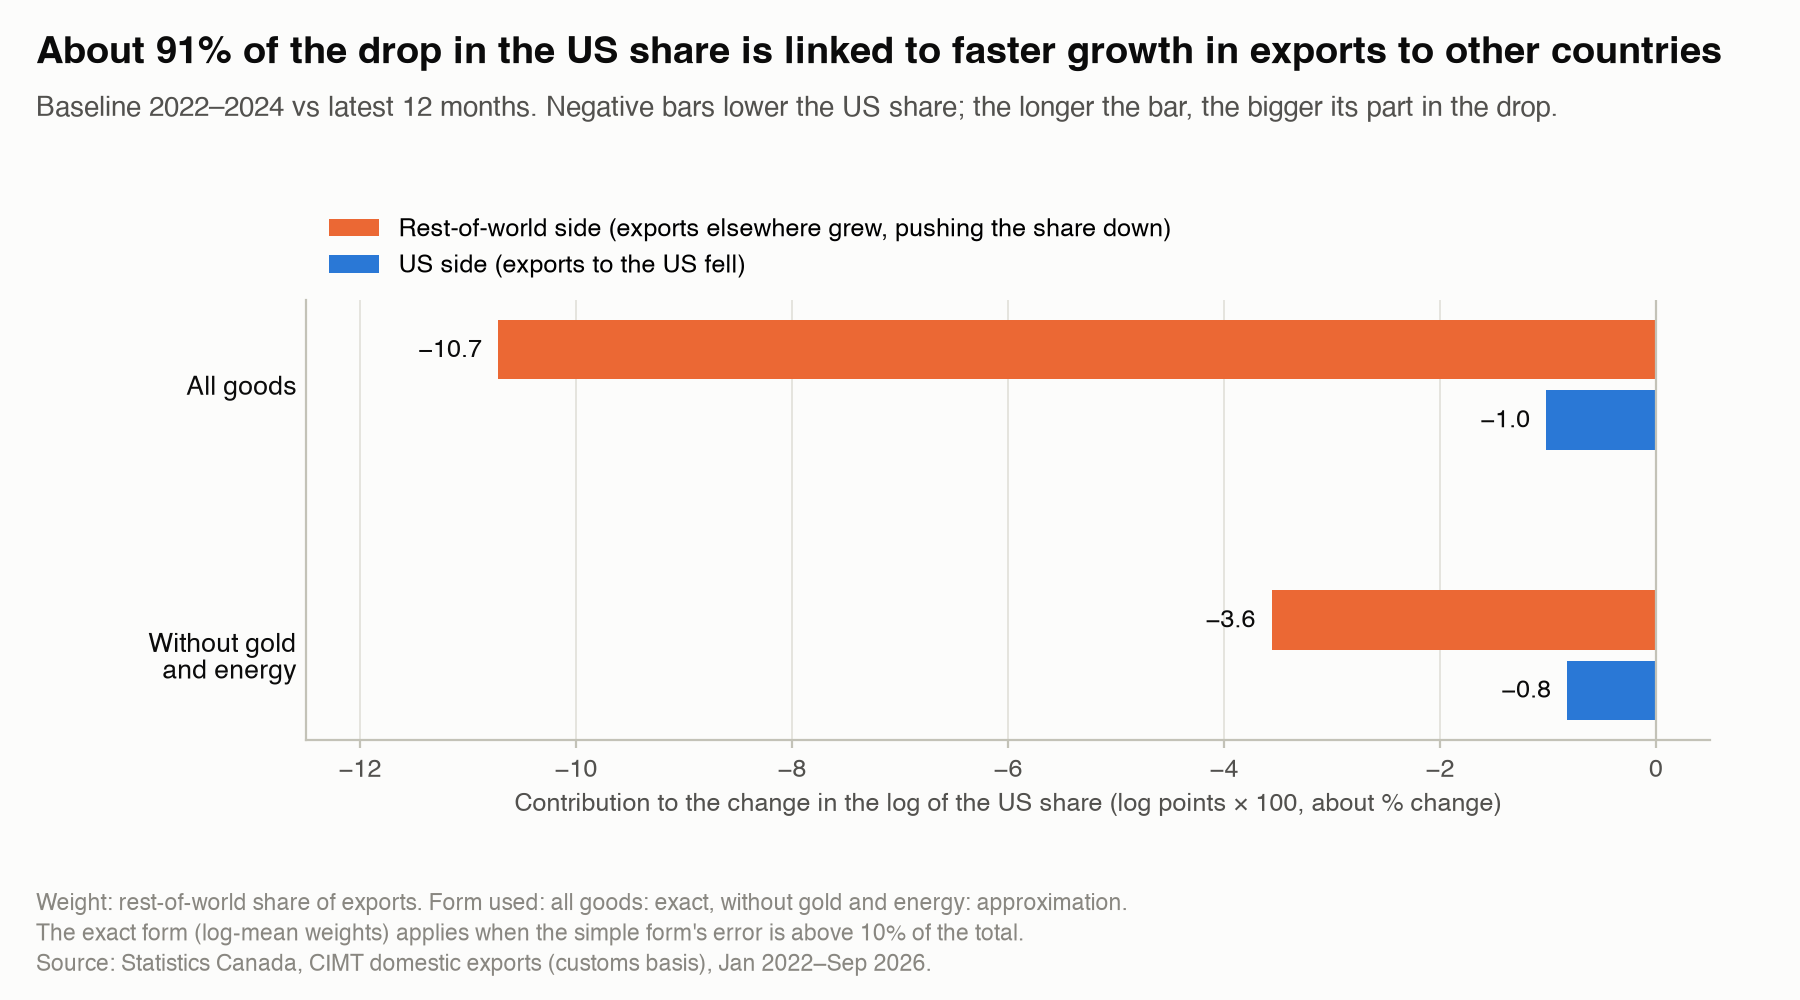

In [5]:
display(Image(filename=str(ROOT / "figures" / "m1_us_share.png"), width=900))
display(Image(filename=str(ROOT / "figures" / "h1_decomposition.png"), width=900))

## Reading

- The decline in the US share is associated mostly with growth in exports to other countries. Exports to the US were slightly lower than in the baseline.
- The pattern holds without gold and energy, but there the share falls much less (see notebook 02).
- This is a description of the data. It does not show that tariffs caused the change.